# Email Spam Classification using KNN and SVM

## Problem Statement
Classify emails using binary classification:
- **0 = Normal / Not Spam**
- **1 = Spam**

Implement **K-Nearest Neighbors (KNN)** and **Support Vector Machine (SVM)** classifiers and compare their performance.

**Dataset:** `emails.csv` from the Kaggle Email Spam Classification Dataset.

The dataset contains 5,172 emails and 3,002 columns: an email identifier, word-frequency features, and a final binary label. The word-frequency columns represent common words appearing in the emails. 


## 1. Import Required Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 2. Upload and Load Dataset

Download `emails.csv` from Kaggle and upload it using the cell below.

In [3]:
# Keep emails.csv in the same folder as this notebook
df = pd.read_csv("emails.csv")

print("Dataset loaded successfully!")
print(df.shape)
df.head()

Dataset loaded successfully!
(5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


## 3. Understand the Dataset

In [4]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Class distribution:")
print(df.iloc[:, -1].value_counts())

Dataset shape: (5172, 3002)
Missing values: 0
Class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


## 4. Data Pre-processing

The first column is the email identifier and is not useful for classification, so it is removed.

The final column is the target:
- `0` → Not Spam
- `1` → Spam

The remaining columns contain word-frequency features.

In [5]:
# Remove the first column (email ID)
df = df.drop(columns=[df.columns[0]])

# Remove missing and duplicate rows
df = df.dropna().drop_duplicates()

# Separate input and output
X = df.iloc[:, :-1]
y = df.iloc[:, -1].astype(int)

print("Data preprocessing completed!")
print("Features:", X.shape)
print("Target:", y.shape)

Data preprocessing completed!
Features: (4631, 3000)
Target: (4631,)


## 5. Visualize Class Distribution

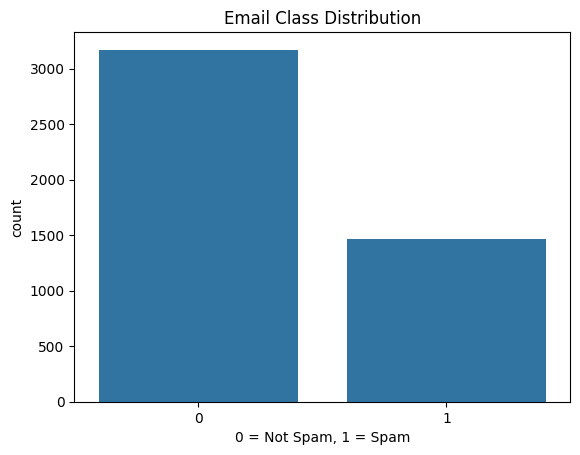

In [6]:
sns.countplot(x=y)
plt.title("Email Class Distribution")
plt.xlabel("0 = Not Spam, 1 = Spam")
plt.show()

## 6. Train-Test Split

We use 80% of the data for training and 20% for testing. `stratify=y` preserves the spam/not-spam proportion in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3704, 3000)
Testing data: (927, 3000)


## 7. Feature Scaling

KNN is distance-based and SVM can also benefit from scaled features. StandardScaler transforms features to approximately zero mean and unit variance.

The scaler is fitted only on the training data to avoid data leakage.

In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


## 8. K-Nearest Neighbors (KNN)

KNN classifies an email according to the majority class among its nearest training examples.

Here, `k=5` is used.

In [9]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

C:\Users\HARSH\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HARSH\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\HARSH\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\HARSH\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\HARSH\AppData\Local\Programs\Python\Python310\lib\subp

KNN Accuracy: 0.8468176914778857


## 9. Support Vector Machine (SVM)

SVM finds a decision boundary that separates the two classes. A linear kernel is used here because the dataset has a large number of word-frequency features and this keeps the practical efficient.

In [10]:
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.9363538295577131


## 10. Model Evaluation

We compare the classifiers using:

- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Percentage of predicted spam emails that are actually spam.
- **Recall:** Percentage of actual spam emails detected by the model.
- **F1 Score:** Harmonic mean of precision and recall.

In [11]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.846818,0.682039,0.962329,0.798295
1,SVM,0.936354,0.884488,0.917808,0.900840


## 11. Confusion Matrices

In [12]:
print("KNN Confusion Matrix:")
print(confusion_matrix(y_test, knn_pred))

print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

KNN Confusion Matrix:
[[504 131]
 [ 11 281]]

SVM Confusion Matrix:
[[600  35]
 [ 24 268]]


## 12. Compare Model Performance

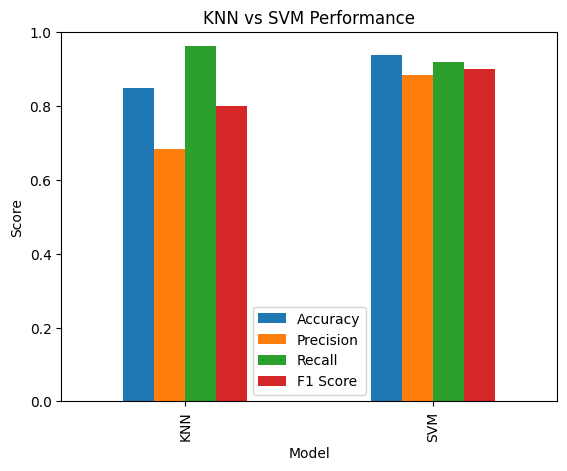

In [13]:
results.set_index("Model").plot(kind="bar")
plt.title("KNN vs SVM Performance")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.show()

## 13. Final Analysis

In [14]:
print(results)

best_model = results.loc[results["F1 Score"].idxmax(), "Model"]
print("Best model:", best_model)

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.846818   0.682039  0.962329  0.798295
1   SVM  0.936354   0.884488  0.917808  0.900840
Best model: SVM


## Conclusion

The email dataset was prepared by removing the identifier column, duplicate records and missing values. The data was split into training and testing sets and the word-frequency features were standardized.

Two binary classification algorithms were implemented:
1. **K-Nearest Neighbors (KNN)**
2. **Support Vector Machine (SVM)**

Their performance was evaluated using **Accuracy, Precision, Recall and F1 Score**, along with confusion matrices.

The final printed comparison should be used to identify the better classifier. For spam detection, **Precision and Recall are particularly important**, because both false spam alerts and missed spam emails matter.

**Result:** The model with the higher F1 Score provides the best balance between detecting spam and avoiding incorrect spam classifications.
